# Sesgo, Varianza y Ruido Irreducible en la Regresión de una Sinusoide Ruidosa

## 1. Marco teórico

Sea el modelo de datos

$$
y = f(x) + \varepsilon, \qquad f(x) = \sin(2\pi x), \qquad \varepsilon \sim \mathcal{N}(0, \sigma^2),
$$

con $x \sim \mathcal{U}[0,1]$. Entrenamos un modelo $\hat f_D(x)$ sobre un conjunto
de entrenamiento $D = \{(x_i, y_i)\}_{i=1}^n$ extraído de la distribución.

El **error cuadrático medio esperado en un punto $x$** (promediado sobre $D$ y
sobre el ruido de la etiqueta $y$ en ese punto) se descompone exactamente como

$$
\mathbb{E}_{D,\,y}\!\left[ \big(y - \hat f_D(x)\big)^2 \right]
= \underbrace{\Big( \mathbb{E}_D[\hat f_D(x)] - f(x) \Big)^2}_{\text{Sesgo}^2(x)}
+ \underbrace{\mathbb{E}_D\!\left[\Big(\hat f_D(x) - \mathbb{E}_D[\hat f_D(x)]\Big)^2\right]}_{\text{Varianza}(x)}
+ \underbrace{\sigma^2}_{\text{Ruido irreducible}}.
$$

En notación abreviada:

$$
\boxed{\;\mathbb{E}\big[(y - \hat f_D(x))^2\big] = \mathrm{Bias}^2(x) + \mathrm{Var}(x) + \sigma^2\;}
$$

El **error de generalización integrado en $x$** es

$$
\mathbb{E}\big[\mathrm{MSE}\big]
= \int \Big[ \mathrm{Bias}^2(x) + \mathrm{Var}(x) \Big]\, p(x)\, dx + \sigma^2,
$$

donde $p(x)$ es la densidad de $x$ (uniforme en $[0,1]$ en este experimento).

## 2. Estimación Monte Carlo

El experimento estima estas tres cantidades en una rejilla de $x$ remuestreando
$M$ conjuntos de entrenamiento independientes:

$$
\widehat{\mathrm{Bias}}^2(x)
= \Big( \tfrac{1}{M}\textstyle\sum_{m=1}^M \hat f_{D_m}(x) - f(x) \Big)^2,
$$

$$
\widehat{\mathrm{Var}}(x)
= \tfrac{1}{M}\textstyle\sum_{m=1}^M
\Big( \hat f_{D_m}(x) - \tfrac{1}{M}\textstyle\sum_{m'=1}^M \hat f_{D_{m'}}(x) \Big)^2,
$$

y $\sigma^2$ se conoce porque lo fijamos nosotros. Así podemos **verificar
numéricamente** que la descomposición se cumple:

$$
\widehat{\mathrm{MSE}}(x) \;\approx\; \widehat{\mathrm{Bias}}^2(x)
+ \widehat{\mathrm{Var}}(x) + \sigma^2.
$$

## 3. Regímenes esperados

| Régimen       | Grado $d$ | $\mathrm{Bias}^2$ | $\mathrm{Var}$ | Interpretación              |
|---------------|-----------|-------------------|----------------|-----------------------------|
| Underfitting  | bajo      | alta              | baja           | modelo demasiado rígido     |
| Good fit      | medio     | baja              | baja           | compromiso óptimo           |
| Overfitting   | alto      | baja              | alta           | modelo demasiado flexible   |

El **ruido irreducible $\sigma^2$** es un piso que ninguna complejidad puede
eliminar: es el límite inferior del error de generalización.


Descomposición integrada:  MSE  vs.  Bias^2 + Var + Noise
  d |    Bias^2 |       Var |   Noise |      Suma |       MSE |      diff
------------------------------------------------------------------------
  0 |    0.5000 |    0.0234 |  0.0625 |    0.5859 |    0.5859 |  1.11e-16
  1 |    0.1964 |    0.0256 |  0.0625 |    0.2845 |    0.2845 |  1.11e-16
  2 |    0.1989 |    0.0674 |  0.0625 |    0.3288 |    0.3288 |  5.55e-17
  3 |    0.0046 |    0.0158 |  0.0625 |    0.0829 |    0.0829 |  1.39e-17
  4 |    0.0059 |    0.0356 |  0.0625 |    0.1040 |    0.1040 |  1.39e-17
  5 |    0.0000 |    0.0558 |  0.0625 |    0.1183 |    0.1183 |  0.00e+00
  6 |    0.0007 |    0.5718 |  0.0625 |    0.6350 |    0.6350 |  1.11e-16
  7 |    0.0083 |    2.5082 |  0.0625 |    2.5790 |    2.5790 |  4.44e-16
  8 |    0.0510 |   11.5678 |  0.0625 |   11.6813 |   11.6813 |  3.55e-15
  9 |    0.9928 |  198.6110 |  0.0625 |  199.6663 |  199.6663 |  0.00e+00
 10 |    0.4039 | 2798.7317 |  0.0625 | 2799.1981 | 27

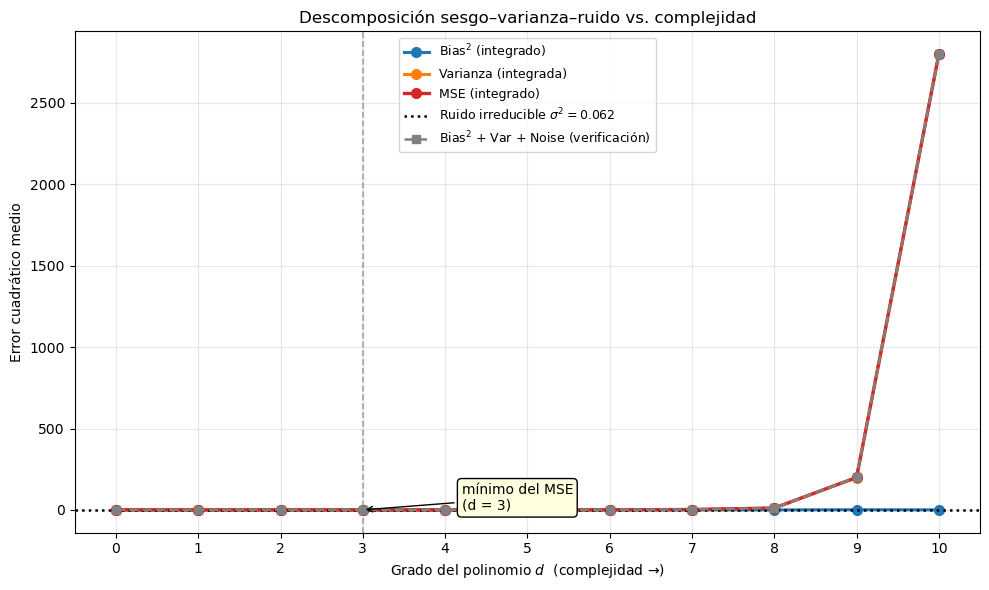

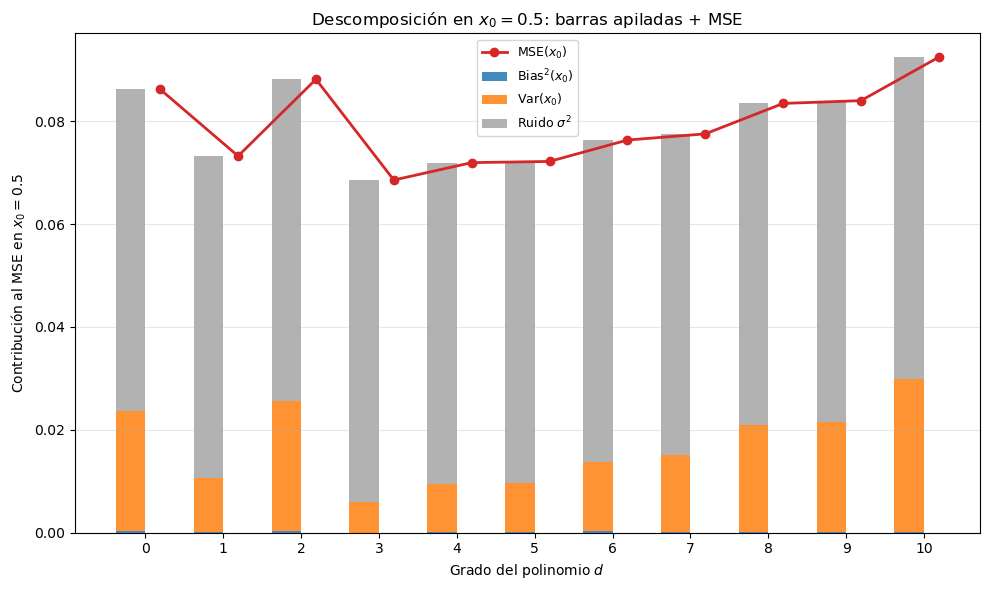

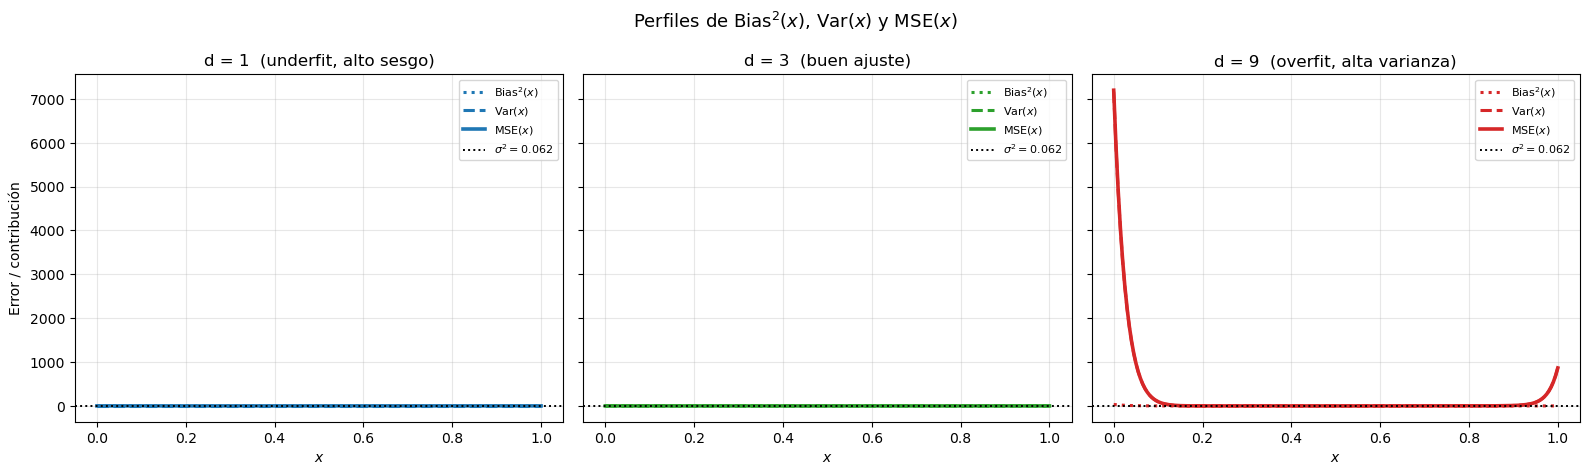

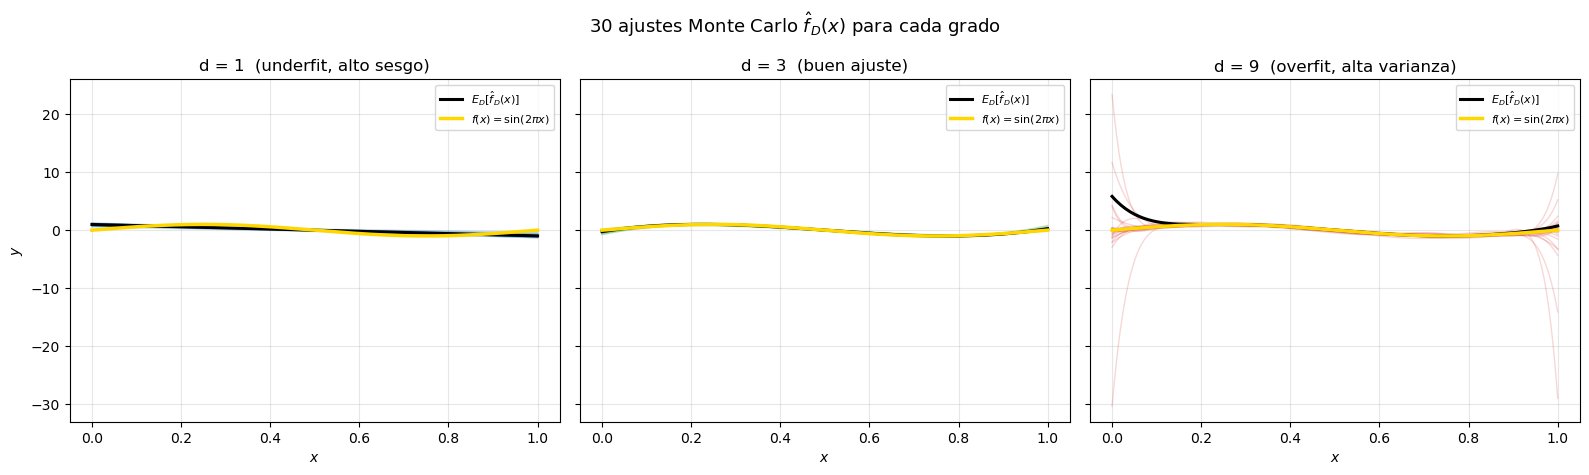


Resumen:
  Grado con menor MSE integrado : 3
  Bias^2 en ese grado           : 0.0046
  Varianza en ese grado         : 0.0158
  Ruido irreducible (sigma^2)   : 0.0625
  MSE = Bias^2 + Var + Noise    : 0.0829

Interpretación:
  * d bajo  -> Bias^2 alto, Var baja  -> UNDERFIT (infraajuste).
  * d medio -> compromiso óptimo      -> GOOD FIT.
  * d alto  -> Bias^2 bajo, Var alta  -> OVERFIT (sobreajuste).
  * El ruido irreducible sigma^2 nunca desaparece.


In [1]:
# =============================================================================
# SESGO–VARIANZA–RUIDO EN LA REGRESIÓN DE UNA SINUSOIDE RUIDOSA
# =============================================================================
#
# Modelo de datos:
#     y = sin(2*pi*x) + eps,   eps ~ N(0, sigma^2),   x ~ U[0,1]
#
# Para cada grado polinómico d = 0..10:
#   * Se generan M conjuntos de entrenamiento independientes.
#   * Se ajusta un polinomio de grado d a cada uno.
#   * Se estiman, en una rejilla de x:
#         Bias^2(x)  = ( E_D[ f_hat(x)] - f(x) )^2
#         Var(x)     = E_D[ (f_hat(x) - E_D[f_hat(x)])^2 ]
#         Noise      = sigma^2   (conocido)
#         MSE(x)     = E_{D,y}[(y - f_hat(x))^2]
#   * Se verifica numéricamente   MSE ≈ Bias^2 + Var + Noise.
#
# Figuras:
#   1. Bias^2, Var y MSE (integrados en x) en función del grado d.
#   2. Descomposición en un punto x0 concreto, en función del grado.
#   3. Curvas Bias^2(x), Var(x) y MSE(x) para tres grados: underfit,
#      good fit, overfit.
#
# Requiere: numpy, matplotlib, scikit-learn
# =============================================================================

import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error


# =============================================================================
# 1. PARÁMETROS
# =============================================================================
RANDOM_SEED = 0
rng = np.random.default_rng(RANDOM_SEED)

N_TRAIN = 25            # tamaño del conjunto de entrenamiento
N_TEST  = 500           # puntos para estimar el MSE de generalización
SIGMA   = 0.25          # desviación típica del ruido
M       = 500           # nº de conjuntos de entrenamiento por grado (Monte Carlo)
DEGREES = list(range(0, 11))
X_PLOT  = np.linspace(0.0, 1.0, 200).reshape(-1, 1)


def true_function(x):
    return np.sin(2 * np.pi * x.ravel())


# =============================================================================
# 2. PIPELINE POLINÓMICO
# =============================================================================
def make_model(degree):
    return Pipeline([
        ("poly", PolynomialFeatures(degree=degree, include_bias=True)),
        ("lin",  LinearRegression(fit_intercept=False)),
    ])


# =============================================================================
# 3. EXPERIMENTO MONTE CARLO
# =============================================================================
# f_hat_all[d] : matriz (M, len(X_PLOT)) con las M predicciones en la rejilla
f_hat_all = {d: np.zeros((M, X_PLOT.shape[0])) for d in DEGREES}

for m in range(M):
    # Un conjunto de entrenamiento nuevo en cada iteración
    x_tr = rng.uniform(0.0, 1.0, size=N_TRAIN)
    y_tr = true_function(x_tr) + rng.normal(0.0, SIGMA, size=N_TRAIN)
    X_tr = x_tr.reshape(-1, 1)

    for d in DEGREES:
        model = make_model(d)
        model.fit(X_tr, y_tr)
        f_hat_all[d][m, :] = model.predict(X_PLOT)


# =============================================================================
# 4. DESCOMPOSICIÓN SESGO–VARIANZA–RUIDO EN LA REJILLA
# =============================================================================
f_true_grid = true_function(X_PLOT)          # f(x) verdadera
noise = SIGMA ** 2                           # ruido irreducible

bias2_grid = {}
var_grid   = {}
mse_grid   = {}

for d in DEGREES:
    f_hat = f_hat_all[d]                     # (M, n_grid)
    mean_pred = f_hat.mean(axis=0)           # E_D[f_hat(x)]

    bias2_grid[d] = (mean_pred - f_true_grid) ** 2
    var_grid[d]   = ((f_hat - mean_pred) ** 2).mean(axis=0)

    # MSE empírico: E_{D,y}[(y - f_hat(x))^2] para y ~ f(x)+eps
    # Se puede calcular analíticamente (para verificar):
    #   E_y[(y - f_hat)^2 | f_hat] = (f - f_hat)^2 + sigma^2
    #   => promedio sobre M
    mse_grid[d] = ((f_true_grid - f_hat) ** 2).mean(axis=0) + noise

# Integración sobre x ~ U[0,1] (regla del trapecio sobre la rejilla)
def integrate_over_x(f_grid):
    return np.trapz(f_grid, X_PLOT.ravel())

bias2_int = np.array([integrate_over_x(bias2_grid[d]) for d in DEGREES])
var_int   = np.array([integrate_over_x(var_grid[d])   for d in DEGREES])
mse_int   = np.array([integrate_over_x(mse_grid[d])   for d in DEGREES])
total     = bias2_int + var_int + noise

print("\nDescomposición integrada:  MSE  vs.  Bias^2 + Var + Noise")
print(f"{'d':>3} | {'Bias^2':>9} | {'Var':>9} | {'Noise':>7} | "
      f"{'Suma':>9} | {'MSE':>9} | {'diff':>9}")
print("-" * 72)
for i, d in enumerate(DEGREES):
    print(f"{d:>3} | {bias2_int[i]:>9.4f} | {var_int[i]:>9.4f} | "
          f"{noise:>7.4f} | {total[i]:>9.4f} | {mse_int[i]:>9.4f} | "
          f"{abs(mse_int[i] - total[i]):>9.2e}")


# =============================================================================
# 5. FIGURA 1 — Bias^2, Var, MSE integrados vs. grado
# =============================================================================
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(DEGREES, bias2_int, "-o", lw=2.2, color="tab:blue",
        markersize=7, label=r"Bias$^2$ (integrado)")
ax.plot(DEGREES, var_int, "-o", lw=2.2, color="tab:orange",
        markersize=7, label="Varianza (integrada)")
ax.plot(DEGREES, mse_int, "-o", lw=2.4, color="tab:red",
        markersize=7, label="MSE (integrado)")
ax.axhline(noise, color="k", linestyle=":", lw=1.8,
           label=rf"Ruido irreducible $\sigma^2={noise:.3f}$")
ax.plot(DEGREES, total, "--s", lw=1.8, color="gray",
        markersize=6, label="Bias$^2$ + Var + Noise (verificación)")

best_d = DEGREES[int(np.argmin(mse_int))]
ax.axvline(best_d, color="gray", lw=1.2, linestyle="--", alpha=0.7)
ax.annotate(f"mínimo del MSE\n(d = {best_d})",
            xy=(best_d, mse_int[best_d]),
            xytext=(best_d + 1.2, mse_int[best_d] + 0.05),
            fontsize=10,
            arrowprops=dict(arrowstyle="->", color="black", lw=1),
            bbox=dict(boxstyle="round,pad=0.3",
                      facecolor="lightyellow", edgecolor="black"))

ax.set_xlabel("Grado del polinomio $d$  (complejidad →)")
ax.set_ylabel("Error cuadrático medio")
ax.set_title("Descomposición sesgo–varianza–ruido vs. complejidad")
ax.set_xticks(DEGREES)
ax.grid(True, alpha=0.3)
ax.legend(loc="upper center", fontsize=9)
plt.tight_layout()
plt.savefig("bias_variance_integrated.png", dpi=120)
plt.show()


# =============================================================================
# 6. FIGURA 2 — Descomposición en un punto x0 concreto
# =============================================================================
x0 = 0.5
idx0 = int(np.argmin(np.abs(X_PLOT.ravel() - x0)))
bias2_x0 = np.array([bias2_grid[d][idx0] for d in DEGREES])
var_x0   = np.array([var_grid[d][idx0]   for d in DEGREES])
mse_x0   = np.array([mse_grid[d][idx0]   for d in DEGREES])

fig, ax = plt.subplots(figsize=(10, 6))
width = 0.38
xs = np.array(DEGREES)
ax.bar(xs - width/2, bias2_x0, width=width, color="tab:blue",
       alpha=0.85, label=r"Bias$^2(x_0)$")
ax.bar(xs - width/2, var_x0, width=width, bottom=bias2_x0,
       color="tab:orange", alpha=0.85, label=r"Var$(x_0)$")
ax.bar(xs - width/2, np.full_like(var_x0, noise), width=width,
       bottom=bias2_x0 + var_x0, color="gray", alpha=0.6,
       label=r"Ruido $\sigma^2$")
ax.plot(xs + width/2, mse_x0, "-o", color="tab:red", lw=2,
        label=r"MSE$(x_0)$")
ax.set_xticks(DEGREES)
ax.set_xlabel("Grado del polinomio $d$")
ax.set_ylabel(rf"Contribución al MSE en $x_0={x0}$")
ax.set_title(rf"Descomposición en $x_0={x0}$: barras apiladas + MSE")
ax.grid(True, alpha=0.3, axis="y")
ax.legend(loc="upper center", fontsize=9)
plt.tight_layout()
plt.savefig("bias_variance_point.png", dpi=120)
plt.show()


# =============================================================================
# 7. FIGURA 3 — Perfiles Bias^2(x), Var(x), MSE(x) para 3 grados
# =============================================================================
example_degrees = [1, 3, 9]     # underfit, good fit, overfit
colors = {1: "tab:blue", 3: "tab:green", 9: "tab:red"}
titles = {1: "d = 1  (underfit, alto sesgo)",
          3: "d = 3  (buen ajuste)",
          9: "d = 9  (overfit, alta varianza)"}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)
for ax, d in zip(axes, example_degrees):
    c = colors[d]
    ax.plot(X_PLOT, bias2_grid[d], lw=2.2, color=c,
            linestyle=":", label=r"Bias$^2(x)$")
    ax.plot(X_PLOT, var_grid[d], lw=2.2, color=c,
            linestyle="--", label="Var$(x)$")
    ax.plot(X_PLOT, mse_grid[d], lw=2.6, color=c,
            linestyle="-", label="MSE$(x)$")
    ax.axhline(noise, color="k", linestyle=":", lw=1.4,
               label=rf"$\sigma^2={noise:.3f}$")
    ax.set_title(titles[d])
    ax.set_xlabel("$x$")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8, loc="upper right")
axes[0].set_ylabel("Error / contribución")
fig.suptitle(r"Perfiles de Bias$^2(x)$, Var$(x)$ y MSE$(x)$", fontsize=13)
plt.tight_layout()
plt.savefig("bias_variance_profiles.png", dpi=120)
plt.show()


# =============================================================================
# 8. FIGURA 4 — Predicciones Monte Carlo para 3 grados
# =============================================================================
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), sharey=True)
for ax, d in zip(axes, example_degrees):
    c = colors[d]
    for m in range(30):                       # 30 curvas de las M
        ax.plot(X_PLOT, f_hat_all[d][m], color=c, alpha=0.18, lw=1)
    ax.plot(X_PLOT, f_hat_all[d].mean(axis=0), color="black",
            lw=2.2, label=r"$E_D[\hat f_D(x)]$")
    ax.plot(X_PLOT, f_true_grid, color="gold", lw=2.5,
            label=r"$f(x)=\sin(2\pi x)$")
    ax.set_title(titles[d])
    ax.set_xlabel("$x$")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8, loc="upper right")
axes[0].set_ylabel("$y$")
fig.suptitle(r"30 ajustes Monte Carlo $\hat f_D(x)$ para cada grado", fontsize=13)
plt.tight_layout()
plt.savefig("bias_variance_mc_curves.png", dpi=120)
plt.show()


# =============================================================================
# 9. RESUMEN
# =============================================================================
print("\nResumen:")
print(f"  Grado con menor MSE integrado : {best_d}")
print(f"  Bias^2 en ese grado           : {bias2_int[best_d]:.4f}")
print(f"  Varianza en ese grado         : {var_int[best_d]:.4f}")
print(f"  Ruido irreducible (sigma^2)   : {noise:.4f}")
print(f"  MSE = Bias^2 + Var + Noise    : "
      f"{bias2_int[best_d] + var_int[best_d] + noise:.4f}")
print()
print("Interpretación:")
print("  * d bajo  -> Bias^2 alto, Var baja  -> UNDERFIT (infraajuste).")
print("  * d medio -> compromiso óptimo      -> GOOD FIT.")
print("  * d alto  -> Bias^2 bajo, Var alta  -> OVERFIT (sobreajuste).")
print("  * El ruido irreducible sigma^2 nunca desaparece.")